# Implementación de Algoritmos de Machine Learning Supervisado
## Caso de estudio: Predicción de lotes defectuosos en producción (XYZ Inc.)

**Universidad de Cundinamarca — Especialización en Inteligencia Artificial**
**Curso:** Introducción a Machine Learning (Periodo 2026-2)
**Docente:** Ing. Wilson Rojas Reales, PhD(c)

---

De los dos casos propuestos en la guía `UC_MLS_IMPL_ALG_STUDY_CASE.pdf`, el grupo seleccionó **"Predicción de defectos en Producción"**. La actividad solicitada es *modificar el script `C1_CasoProduccion.py` para incluir todas las métricas estudiadas e interpretar cada una de ellas para cada uno de los modelos implementados*.

El cuaderno se organiza así:

* **Parte A – Caso de estudio seleccionado (principal):** se entrenan y evalúan los seis algoritmos (Regresión Logística, Árbol de Decisión, Random Forest, SVM, KNN y Naive Bayes) con todas las métricas, matrices de confusión, una evaluación más exigente (validación cruzada repetida y *Leave-One-Out*), el análisis de probabilidades, la interpretabilidad de los modelos y la predicción de un lote nuevo.
* **Parte B – Validación complementaria con un dataset estándar:** se aplica exactamente el mismo flujo al dataset *Breast Cancer Wisconsin* de `sklearn.datasets` (569 registros), para comprobar el comportamiento de los algoritmos con un volumen de datos mayor.

> ▶️ **Cómo ejecutarlo en Google Colab:** `Entorno de ejecución → Ejecutar todas` (`Ctrl + F9`). Las celdas dependen de las anteriores, por lo que deben ejecutarse **en orden, de arriba hacia abajo**. Si el entorno se reinicia, vuelva a ejecutar todo.

> **Clase positiva.** La clase **1 = lote defectuoso** es el evento que no queremos dejar pasar. Por eso, como indica la guía, el **Recall** es la métrica prioritaria: un **falso negativo** es un lote defectuoso que llega al cliente.

## 1. Importación de librerías

In [1]:
# ------------------------------------------------------------
# Librerías de manipulación de datos y visualización
# ------------------------------------------------------------
import numpy as np                 # Cálculo numérico y arreglos
import pandas as pd                # Estructuras tabulares (DataFrame)
import matplotlib.pyplot as plt    # Gráficos base
import seaborn as sns              # Gráficos estadísticos (heatmaps, barras)

# ------------------------------------------------------------
# Scikit-learn: datos, preparación, modelos y métricas
# ------------------------------------------------------------
from sklearn.datasets import load_breast_cancer                # Dataset estándar (Parte B)
from sklearn.model_selection import (train_test_split,         # División train/test
                                     StratifiedKFold,          # Particiones estratificadas
                                     RepeatedStratifiedKFold,  # Validación cruzada repetida
                                     LeaveOneOut,              # Deja uno fuera (datasets pequeños)
                                     cross_val_score, cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler               # Estandarización (media 0, desv. 1)
from sklearn.pipeline import Pipeline                          # Escalado + modelo sin fuga de datos

# Los seis algoritmos de clasificación solicitados
from sklearn.linear_model import LogisticRegression            # Regresión Logística
from sklearn.tree import DecisionTreeClassifier, plot_tree     # Árbol de Decisión (y su gráfico)
from sklearn.ensemble import RandomForestClassifier            # Random Forest (ensamble de árboles)
from sklearn.svm import SVC                                    # Máquina de Vectores de Soporte
from sklearn.neighbors import KNeighborsClassifier             # K vecinos más cercanos
from sklearn.naive_bayes import GaussianNB                     # Naive Bayes gaussiano

# Métricas de evaluación
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

import warnings
warnings.filterwarnings("ignore")      # Silencia avisos no críticos para una salida limpia

# Semilla global para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

# Estilo gráfico y color fijo por modelo (el mismo color identifica al modelo en todos los gráficos)
sns.set_theme(style="whitegrid", context="notebook")
COLORES = {
    "Regresión Logística": "#2a78d6",
    "Árbol de Decisión":   "#eb6834",
    "Random Forest":       "#1baf7a",
    "SVM":                 "#eda100",
    "KNN":                 "#e87ba4",
    "Naive Bayes":         "#4a3aa7",
}
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Funciones auxiliares

Para no repetir código, se definen funciones que se reutilizan tanto en el caso de estudio (Parte A) como en la validación complementaria (Parte B):

* `crear_modelos()` → los seis clasificadores, cada uno dentro de un `Pipeline` (escalado → modelo).
* `evaluar_modelos()` → entrena, predice y calcula **todas** las métricas y la matriz de confusión.
* `graficar_matrices()` y `graficar_metricas()` → visualizaciones comparativas.

In [2]:
def crear_modelos():
    # Devuelve {nombre: Pipeline(escalado + clasificador)} con instancias nuevas (sin entrenar).
    # El escalado es imprescindible para Regresión Logística, SVM y KNN; en árboles y Naive Bayes
    # no altera el resultado, pero mantiene un flujo homogéneo y evita fuga de datos en la validación cruzada.
    base = {
        "Regresión Logística": LogisticRegression(max_iter=1000, random_state=SEED),
        "Árbol de Decisión":   DecisionTreeClassifier(random_state=SEED),
        "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=SEED),
        "SVM":                 SVC(kernel="rbf", probability=True, random_state=SEED),
        "KNN":                 KNeighborsClassifier(n_neighbors=5),
        "Naive Bayes":         GaussianNB(),
    }
    return {nombre: Pipeline([("escalado", StandardScaler()), ("modelo", m)])
            for nombre, m in base.items()}


def evaluar_modelos(modelos, X_train, X_test, y_train, y_test, etiquetas, n_cv=5, verbose=True):
    # Entrena cada modelo y calcula: Accuracy, Precision, Recall, Especificidad, F1, ROC-AUC,
    # validación cruzada (recall) y la matriz de confusión [[TN, FP], [FN, TP]].
    resultados, matrices, probabilidades = [], {}, {}
    cv = StratifiedKFold(n_splits=n_cv, shuffle=True, random_state=SEED)

    for nombre, modelo in modelos.items():
        modelo.fit(X_train, y_train)                    # 1) Entrenamiento
        y_pred = modelo.predict(X_test)                 # 2) Predicción de la clase
        y_prob = modelo.predict_proba(X_test)[:, 1]     #    y probabilidad de la clase positiva (1)

        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])   # 3) Matriz de confusión
        tn, fp, fn, tp = cm.ravel()

        # 4) Validación cruzada sobre entrenamiento (el Pipeline re-escala en cada partición)
        cv_recall = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="recall")

        resultados.append({
            "Modelo":        nombre,
            "Accuracy":      accuracy_score(y_test, y_pred),
            "Precision":     precision_score(y_test, y_pred, zero_division=0),
            "Recall":        recall_score(y_test, y_pred, zero_division=0),
            "Especificidad": tn / (tn + fp) if (tn + fp) else 0.0,
            "F1-score":      f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC":       roc_auc_score(y_test, y_prob),
            "CV Recall (media)": cv_recall.mean(),
            "CV Recall (desv.)": cv_recall.std(),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        })
        matrices[nombre] = cm
        probabilidades[nombre] = y_prob

        if verbose:
            print("=" * 66)
            print(f"MODELO: {nombre}")
            print("=" * 66)
            print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
            print(classification_report(y_test, y_pred, digits=3, zero_division=0,
                                        target_names=etiquetas))
    return pd.DataFrame(resultados), matrices, probabilidades


def graficar_matrices(matrices, etiquetas, titulo):
    # Cuadrícula 2x3 con la matriz de confusión de cada modelo, anotando TN / FP / FN / TP.
    fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
    nombres_celda = np.array([["TN", "FP"], ["FN", "TP"]])
    for ax, (nombre, cm) in zip(axes.ravel(), matrices.items()):
        anot = np.array([[f"{cm[i, j]}\n{nombres_celda[i, j]}" for j in range(2)] for i in range(2)])
        sns.heatmap(cm, annot=anot, fmt="", cmap="Blues", cbar=False, ax=ax,
                    linewidths=2, linecolor="white", annot_kws={"fontsize": 13},
                    xticklabels=etiquetas, yticklabels=etiquetas)
        ax.set_title(nombre, fontsize=12, fontweight="bold")
        ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
    fig.suptitle(titulo, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


def graficar_metricas(res, titulo, metricas=("Accuracy", "Precision", "Recall", "F1-score"), ymin=None):
    # Barras agrupadas: un color fijo por modelo, un grupo por métrica.
    largo = res.melt(id_vars="Modelo", value_vars=list(metricas), var_name="Métrica", value_name="Valor")
    fig, ax = plt.subplots(figsize=(13, 5))
    sns.barplot(data=largo, x="Métrica", y="Valor", hue="Modelo", palette=COLORES,
                hue_order=list(COLORES), ax=ax, edgecolor="white", linewidth=1.5)
    ax.set_ylim(ymin if ymin is not None else max(0.0, largo["Valor"].min() - 0.05), 1.0)
    ax.set_title(titulo, fontsize=13, fontweight="bold")
    ax.set_xlabel(""); ax.set_ylabel("Valor de la métrica")
    ax.legend(title="Modelo", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
    plt.tight_layout()
    plt.show()

print("Funciones auxiliares definidas.")

Funciones auxiliares definidas.


# PARTE A — Caso de estudio: Predicción de defectos en producción

## 3. Contexto del problema

La empresa manufacturera **XYZ Inc.** desea predecir si un lote de producción saldrá **defectuoso (1)** o **no defectuoso (0)** a partir de cinco variables del proceso:

| Variable | Descripción |
|---|---|
| `temperatura` | Temperatura de la máquina |
| `presion` | Presión del sistema |
| `velocidad` | Velocidad de producción |
| `horas_operacion` | Horas continuas de uso de la máquina |
| `vibracion` | Nivel de vibración de la máquina |

Un lote defectuoso genera pérdidas económicas, reprocesos, devoluciones, desperdicio de materia prima y afectación de la calidad. Según la guía:

* **Falso positivo (FP):** el modelo dice que el lote es defectuoso, pero no lo es → costo de una **inspección innecesaria**.
* **Falso negativo (FN):** el modelo dice que el lote está bien, pero es defectuoso → el defecto **llega al cliente** (error más costoso).

> *"El mejor modelo no siempre es el que acierta, sino el que mejor ayuda a prevenir defectos antes de que lleguen al cliente."*

## 4. Carga y exploración de los datos

In [3]:
# Dataset simulado de producción (idéntico al del script C1_CasoProduccion.py de la guía)
# defectuoso: 0 = lote correcto | 1 = lote defectuoso
data = {
    "temperatura":     [70, 72, 75, 80, 85, 90, 95, 100, 78, 82, 88, 92, 97, 76, 73, 89, 94, 99, 81, 86],
    "presion":         [30, 32, 34, 36, 40, 42, 45, 48, 35, 37, 41, 43, 46, 33, 31, 42, 44, 47, 36, 39],
    "velocidad":       [120, 118, 115, 110, 105, 100, 95, 90, 112, 108, 102, 98, 93, 116, 119, 101, 96, 91, 109, 104],
    "horas_operacion": [2, 3, 4, 6, 8, 10, 12, 14, 5, 7, 9, 11, 13, 4, 3, 10, 12, 15, 6, 8],
    "vibracion":       [1.2, 1.4, 1.6, 2.0, 2.5, 3.0, 3.5, 4.0, 1.8, 2.2, 2.8, 3.2, 3.7, 1.5, 1.3, 3.1, 3.6, 4.2, 2.1, 2.6],
    "defectuoso":      [0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1],
}
df = pd.DataFrame(data)
df.index = [f"Lote {i + 1}" for i in range(len(df))]   # Identificador legible de cada lote

print("Dimensiones del dataset:", df.shape)
print("Valores nulos:", int(df.isnull().sum().sum()))
conteo = df["defectuoso"].value_counts().rename({0: "No defectuoso (0)", 1: "Defectuoso (1)"})
print("\nDistribución de la variable objetivo:")
print(pd.DataFrame({"n": conteo, "%": (conteo / len(df) * 100).round(1)}))

print("\nPromedio de cada variable según la clase:")
display(df.groupby("defectuoso").mean().round(2))

Dimensiones del dataset: (20, 6)
Valores nulos: 0

Distribución de la variable objetivo:
                    n     %
defectuoso                 
Defectuoso (1)     11  55.0
No defectuoso (0)   9  45.0

Promedio de cada variable según la clase:


,temperatura,presion,velocidad,horas_operacion,vibracion
defectuoso,,,,,
0,76.33,33.78,114.11,4.44,1.68
1,92.27,43.36,97.73,11.09,3.29


Temperatura máx. de lotes NO defectuosos: 82
Temperatura mín. de lotes defectuosos:    85


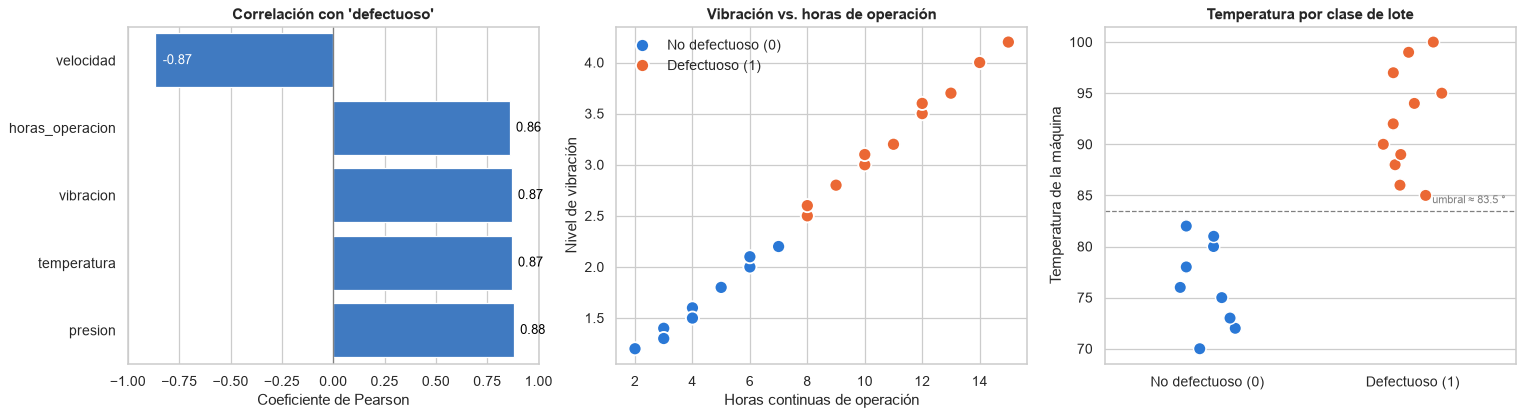

In [4]:
# ------------------------------------------------------------
# Exploración visual: correlación con el defecto y separabilidad de las clases
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
paleta_clase = {"No defectuoso (0)": "#2a78d6", "Defectuoso (1)": "#eb6834"}
clase_txt = df["defectuoso"].map({0: "No defectuoso (0)", 1: "Defectuoso (1)"})

# (a) Correlación de Pearson de cada variable con 'defectuoso'
corr = df.corr()["defectuoso"].drop("defectuoso").sort_values()
sns.barplot(x=corr.values, y=corr.index, ax=axes[0], color="#2a78d6")
axes[0].axvline(0, color="grey", lw=1)
axes[0].set_xlim(-1, 1)
axes[0].set_title("Correlación con 'defectuoso'", fontweight="bold")
axes[0].set_xlabel("Coeficiente de Pearson"); axes[0].set_ylabel("")
for i, v in enumerate(corr.values):
    # Etiqueta junto a la barra (positiva) o dentro de ella (negativa) para no chocar con el eje
    axes[0].text(v + 0.03 if v > 0 else v + 0.04, i, f"{v:.2f}", va="center", ha="left",
                 fontsize=10, color="black" if v > 0 else "white")

# (b) Vibración vs. horas de operación, coloreado por clase
sns.scatterplot(x=df["horas_operacion"], y=df["vibracion"], hue=clase_txt, palette=paleta_clase,
                s=110, edgecolor="white", linewidth=1.5, ax=axes[1])
axes[1].set_title("Vibración vs. horas de operación", fontweight="bold")
axes[1].set_xlabel("Horas continuas de operación"); axes[1].set_ylabel("Nivel de vibración")
axes[1].legend(title="", frameon=False)

# (c) Temperatura por clase: un único umbral separa ambos grupos
sns.stripplot(x=clase_txt, y=df["temperatura"], hue=clase_txt, palette=paleta_clase,
              size=10, jitter=0.15, edgecolor="white", linewidth=1.2, ax=axes[2], legend=False)
axes[2].axhline(83.5, ls="--", color="grey", lw=1)
axes[2].text(1.45, 84, "umbral ≈ 83.5 °", color="grey", ha="right", va="bottom", fontsize=9)
axes[2].set_title("Temperatura por clase de lote", fontweight="bold")
axes[2].set_xlabel(""); axes[2].set_ylabel("Temperatura de la máquina")

plt.tight_layout()
plt.show()

print("Temperatura máx. de lotes NO defectuosos:", df.loc[df.defectuoso == 0, "temperatura"].max())
print("Temperatura mín. de lotes defectuosos:   ", df.loc[df.defectuoso == 1, "temperatura"].min())

**Lectura de la exploración.** Las cinco variables están fuertemente correlacionadas con el defecto (|r| ≈ 0.86–0.88): a mayor temperatura, presión, horas de operación y vibración —y a menor velocidad— mayor probabilidad de defecto. Además, las variables están muy correlacionadas **entre sí** (todas describen el desgaste progresivo de la máquina) y las clases son **separables**: un solo umbral de temperatura (≈ 83.5 °) divide ambos grupos. Esto anticipa que la mayoría de los modelos acertará en el conjunto de prueba.

## 5. Preparación de los datos

Se usa la misma partición que el script de la guía: **70 % entrenamiento / 30 % prueba**, `random_state=42` y `stratify=y` para conservar la proporción de lotes defectuosos. El escalado (`StandardScaler`) se aplica dentro de cada `Pipeline`, ajustándose **solo con los datos de entrenamiento**.

In [5]:
# Variables predictoras (X) y variable objetivo (y)
X = df.drop(columns="defectuoso")
y = df["defectuoso"]

# División estratificada 70/30 (igual que C1_CasoProduccion.py)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

print(f"Entrenamiento: {len(X_train)} lotes | Prueba: {len(X_test)} lotes")
print(f"Defectuosos -> train: {int(y_train.sum())}/{len(y_train)} | test: {int(y_test.sum())}/{len(y_test)}")
print("\nLotes del conjunto de prueba:")
display(X_test.assign(defectuoso=y_test))

Entrenamiento: 14 lotes | Prueba: 6 lotes
Defectuosos -> train: 8/14 | test: 3/6

Lotes del conjunto de prueba:


,temperatura,presion,velocidad,horas_operacion,vibracion,defectuoso
Lote 9,78,35,112,5,1.8,0
Lote 7,95,45,95,12,3.5,1
Lote 14,76,33,116,4,1.5,0
Lote 13,97,46,93,13,3.7,1
Lote 16,89,42,101,10,3.1,1
Lote 4,80,36,110,6,2.0,0


## 6. Definición de los modelos

| Modelo | Hiperparámetros | Idea principal |
|---|---|---|
| Regresión Logística | `max_iter=1000`, L2, `C=1` | Probabilidad mediante la función sigmoide; frontera lineal. |
| Árbol de Decisión | Gini, sin límite de profundidad | Reglas *si-entonces* sobre umbrales de las variables. |
| Random Forest | `n_estimators=100` | 100 árboles con *bagging* que votan por mayoría. |
| SVM | `kernel="rbf"`, `probability=True` | Frontera de máximo margen no lineal. |
| KNN | `n_neighbors=5` | Clase mayoritaria de los 5 lotes más parecidos. |
| Naive Bayes | `GaussianNB()` | Teorema de Bayes asumiendo independencia entre variables. |

In [6]:
modelos = crear_modelos()
for nombre, pipe in modelos.items():
    print(f"• {nombre:<20} -> {pipe.named_steps['modelo']}")

• Regresión Logística  -> LogisticRegression(max_iter=1000, random_state=42)
• Árbol de Decisión    -> DecisionTreeClassifier(random_state=42)
• Random Forest        -> RandomForestClassifier(random_state=42)
• SVM                  -> SVC(probability=True, random_state=42)
• KNN                  -> KNeighborsClassifier()
• Naive Bayes          -> GaussianNB()


## 7. Entrenamiento y evaluación con TODAS las métricas

| Métrica | Fórmula | Pregunta que responde en el caso |
|---|---|---|
| **Accuracy** | (TP+TN)/Total | ¿Qué porcentaje de lotes clasificó bien? |
| **Precision** | TP/(TP+FP) | De los lotes que marcó como defectuosos, ¿cuántos lo eran? (evita inspecciones innecesarias) |
| **Recall** | TP/(TP+FN) | De los lotes realmente defectuosos, ¿cuántos detectó? (**evita que el defecto llegue al cliente**) |
| **Especificidad** | TN/(TN+FP) | De los lotes buenos, ¿cuántos reconoció como buenos? |
| **F1-score** | 2·P·R/(P+R) | Equilibrio entre Precision y Recall |
| **ROC-AUC** | Área bajo la curva ROC | ¿Ordena bien los lotes por riesgo, para cualquier umbral? |
| **Validación cruzada** | Promedio en *k* particiones | ¿El resultado es estable o fue suerte de una partición? |

In [7]:
ETIQUETAS_PROD = ["No defectuoso (0)", "Defectuoso (1)"]

# Con solo 14 lotes de entrenamiento, la validación cruzada interna usa 3 particiones
res_prod, cms_prod, probs_prod = evaluar_modelos(
    modelos, X_train, X_test, y_train, y_test, ETIQUETAS_PROD, n_cv=3)

# Validación cruzada de 5 particiones sobre los 20 lotes (procedimiento del script original)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
res_prod["CV Accuracy (20 lotes)"] = [cross_val_score(m, X, y, cv=cv5, scoring="accuracy").mean()
                                      for m in crear_modelos().values()]

MODELO: Regresión Logística
TN=3  FP=0  FN=0  TP=3
                   precision    recall  f1-score   support

No defectuoso (0)      1.000     1.000     1.000         3
   Defectuoso (1)      1.000     1.000     1.000         3

         accuracy                          1.000         6
        macro avg      1.000     1.000     1.000         6
     weighted avg      1.000     1.000     1.000         6

MODELO: Árbol de Decisión
TN=3  FP=0  FN=0  TP=3
                   precision    recall  f1-score   support

No defectuoso (0)      1.000     1.000     1.000         3
   Defectuoso (1)      1.000     1.000     1.000         3

         accuracy                          1.000         6
        macro avg      1.000     1.000     1.000         6
     weighted avg      1.000     1.000     1.000         6

MODELO: Random Forest
TN=3  FP=0  FN=0  TP=3
                   precision    recall  f1-score   support

No defectuoso (0)      1.000     1.000     1.000         3
   Defectuoso (1)     

In [8]:
metricas = ["Accuracy", "Precision", "Recall", "Especificidad", "F1-score", "ROC-AUC"]
print("TABLA COMPARATIVA — conjunto de prueba (6 lotes)")
display(res_prod[["Modelo"] + metricas + ["CV Accuracy (20 lotes)", "TN", "FP", "FN", "TP"]].round(3))

TABLA COMPARATIVA — conjunto de prueba (6 lotes)


,Modelo,Accuracy,Precision,Recall,Especificidad,F1-score,ROC-AUC,CV Accuracy (20 lotes),TN,FP,FN,TP
0,Regresión Logística,1.0,1.0,1.0,1.0,1.0,1.0,1.00,3,0,0,3
1,Árbol de Decisión,1.0,1.0,1.0,1.0,1.0,1.0,0.95,3,0,0,3
2,Random Forest,1.0,1.0,1.0,1.0,1.0,1.0,1.00,3,0,0,3
3,SVM,1.0,1.0,1.0,1.0,1.0,1.0,1.00,3,0,0,3
4,KNN,1.0,1.0,1.0,1.0,1.0,1.0,1.00,3,0,0,3
5,Naive Bayes,1.0,1.0,1.0,1.0,1.0,1.0,1.00,3,0,0,3


## 8. Matrices de confusión

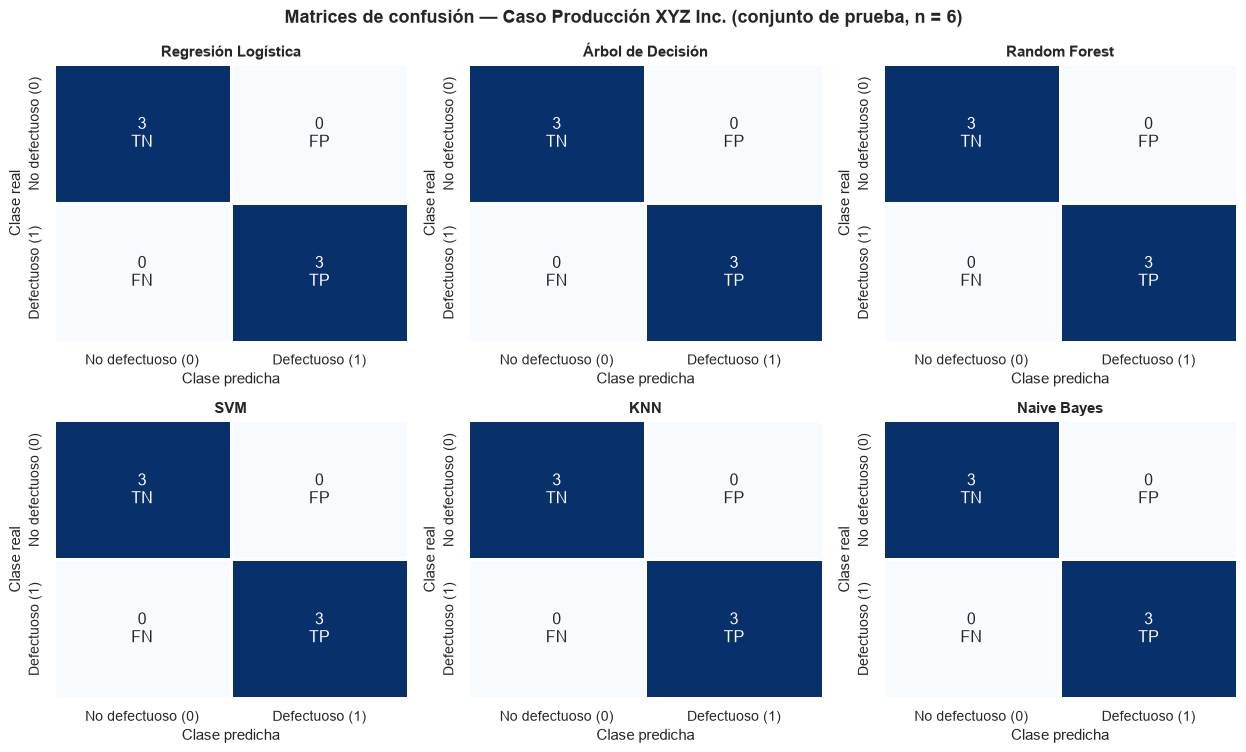

In [9]:
graficar_matrices(cms_prod, ETIQUETAS_PROD,
                  "Matrices de confusión — Caso Producción XYZ Inc. (conjunto de prueba, n = 6)")

## 9. ¿Por qué todos aciertan? Evaluación más exigente

Con solo **6 lotes de prueba**, un único error movería el Recall de 1.00 a 0.67, y una sola partición puede ser "afortunada". Para diferenciar a los modelos se aplican dos técnicas más rigurosas sobre los 20 lotes:

1. **Validación cruzada estratificada repetida (5 particiones × 20 repeticiones = 100 evaluaciones):** cada modelo se entrena y evalúa 100 veces con particiones distintas.
2. **Leave-One-Out (LOO):** se entrena con 19 lotes y se predice el lote restante, 20 veces; se obtiene una matriz de confusión con los 20 lotes.

In [10]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=SEED)
filas = []
for nombre, modelo in crear_modelos().items():
    # 100 evaluaciones con distintas particiones
    r = cross_validate(modelo, X, y, cv=rcv, scoring=["accuracy", "precision", "recall", "f1"])
    # Leave-One-Out: una predicción "fuera de muestra" para cada lote
    y_loo = cross_val_predict(modelo, X, y, cv=LeaveOneOut())
    tn, fp, fn, tp = confusion_matrix(y, y_loo, labels=[0, 1]).ravel()
    filas.append({
        "Modelo": nombre,
        "Accuracy":  r["test_accuracy"].mean(),
        "Precision": r["test_precision"].mean(),
        "Recall":    r["test_recall"].mean(),
        "F1-score":  r["test_f1"].mean(),
        "Desv. F1":  r["test_f1"].std(),
        "LOO FP": fp, "LOO FN": fn,
    })
res_rcv = pd.DataFrame(filas)
print("VALIDACIÓN CRUZADA REPETIDA (100 evaluaciones) + LEAVE-ONE-OUT (20 lotes)")
display(res_rcv.round(3))

VALIDACIÓN CRUZADA REPETIDA (100 evaluaciones) + LEAVE-ONE-OUT (20 lotes)


,Modelo,Accuracy,Precision,Recall,F1-score,Desv. F1,LOO FP,LOO FN
0,Regresión Logística,1.000,1.000,1.000,1.000,0.000,0,0
1,Árbol de Decisión,0.970,0.963,0.983,0.969,0.121,1,0
2,Random Forest,1.000,1.000,1.000,1.000,0.000,0,0
3,SVM,0.992,0.990,1.000,0.994,0.034,0,0
4,KNN,0.988,0.987,0.997,0.990,0.044,0,0
5,Naive Bayes,0.995,0.993,1.000,0.996,0.028,0,0


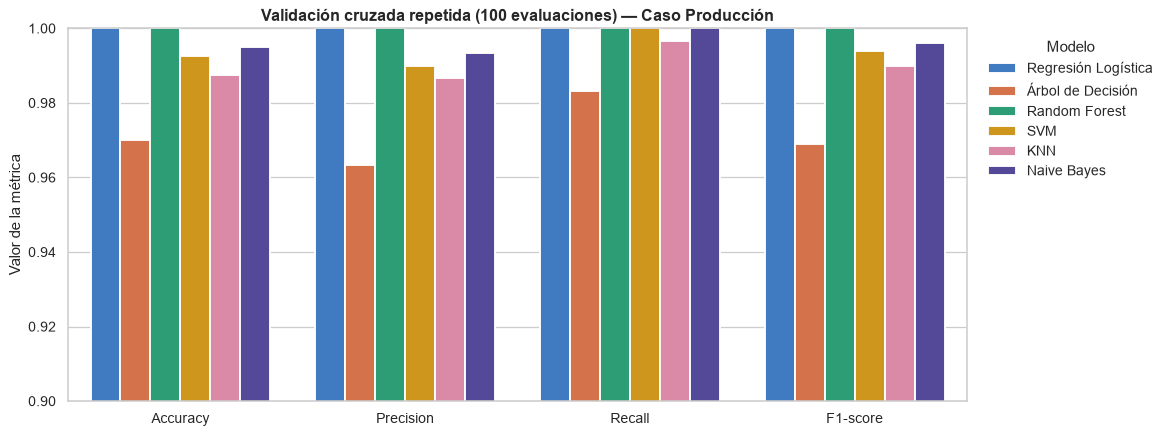

In [11]:
graficar_metricas(res_rcv, "Validación cruzada repetida (100 evaluaciones) — Caso Producción",
                  metricas=("Accuracy", "Precision", "Recall", "F1-score"), ymin=0.90)

## 10. Probabilidades por lote: ¿qué tan seguro está cada modelo?

Las métricas solo cuentan aciertos y errores con el umbral 0.5. La **probabilidad de defecto** muestra qué tan cerca estuvo cada lote del umbral; un lote con probabilidad cercana a 0.5 es un caso **frontera**, donde un pequeño cambio en el proceso puede cambiar la decisión.

In [12]:
tabla_prob = pd.DataFrame(probs_prod, index=X_test.index).round(2)
tabla_prob.insert(0, "Real", y_test.values)
print("Probabilidad estimada de que el lote sea DEFECTUOSO (conjunto de prueba)")
display(tabla_prob)

Probabilidad estimada de que el lote sea DEFECTUOSO (conjunto de prueba)


,Real,Regresión Logística,Árbol de Decisión,Random Forest,SVM,KNN,Naive Bayes
Lote 9,0,0.16,0.0,0.00,0.09,0.0,0.0
Lote 7,1,0.98,1.0,1.00,0.92,1.0,1.0
Lote 14,0,0.07,0.0,0.00,0.06,0.0,0.0
Lote 13,1,0.99,1.0,1.00,0.91,1.0,1.0
Lote 16,1,0.91,1.0,1.00,0.91,1.0,1.0
Lote 4,0,0.27,0.0,0.02,0.17,0.4,0.0


## 11. Interpretabilidad: ¿qué variables explican el defecto?

Además de acertar, la empresa necesita **entender** por qué un lote sale defectuoso para actuar sobre el proceso. Se analizan tres modelos que permiten interpretación directa:

* **Regresión Logística:** coeficientes sobre variables estandarizadas; `exp(β)` es el factor por el que se multiplica la razón de probabilidades (*odds*) de defecto cuando la variable aumenta una desviación estándar.
* **Árbol de Decisión:** las reglas aprendidas.
* **Random Forest:** importancia relativa de cada variable.

Regla del árbol: si horas_operacion <= 7.5 -> No defectuoso; en otro caso -> Defectuoso


,Coef. Regresión Logística (β),Odds ratio exp(β),Importancia Random Forest
temperatura,0.642,1.900,0.22
presion,0.714,2.042,0.19
velocidad,-0.635,0.530,0.15
horas_operacion,0.587,1.799,0.23
vibracion,0.625,1.869,0.21


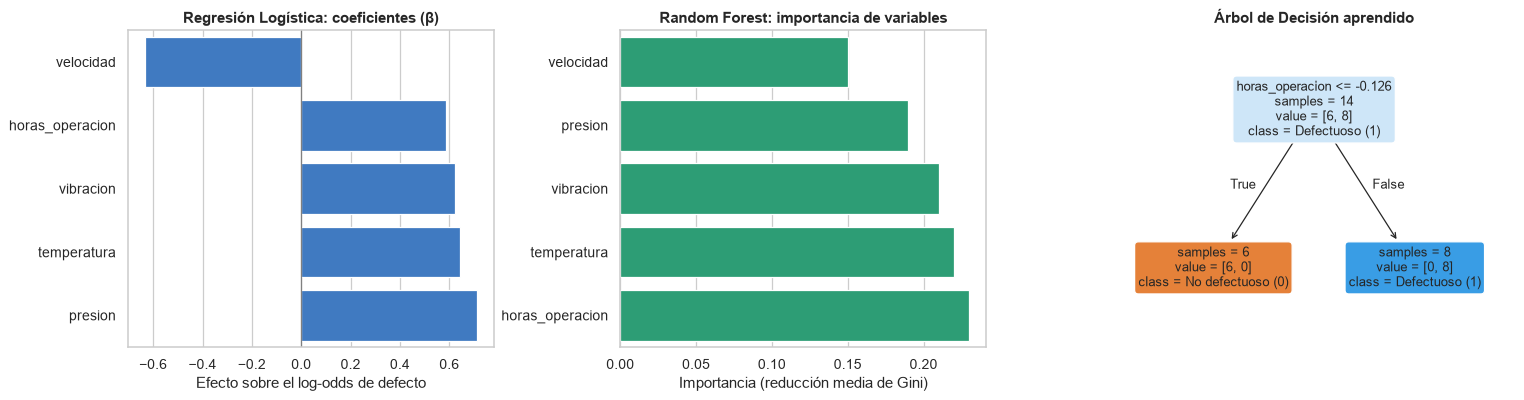

In [13]:
# Modelos ya entrenados en la sección 7
lr   = modelos["Regresión Logística"].named_steps["modelo"]
tree = modelos["Árbol de Decisión"].named_steps["modelo"]
rf   = modelos["Random Forest"].named_steps["modelo"]

interpretacion = pd.DataFrame({
    "Coef. Regresión Logística (β)": lr.coef_[0],
    "Odds ratio exp(β)":             np.exp(lr.coef_[0]),
    "Importancia Random Forest":     rf.feature_importances_,
}, index=X.columns).round(3)
display(interpretacion)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.1]})

# (a) Coeficientes de la Regresión Logística
coef = interpretacion["Coef. Regresión Logística (β)"].sort_values()
sns.barplot(x=coef.values, y=coef.index, ax=axes[0], color=COLORES["Regresión Logística"])
axes[0].axvline(0, color="grey", lw=1)
axes[0].set_title("Regresión Logística: coeficientes (β)", fontweight="bold")
axes[0].set_xlabel("Efecto sobre el log-odds de defecto"); axes[0].set_ylabel("")

# (b) Importancia de variables en Random Forest
imp = interpretacion["Importancia Random Forest"].sort_values()
sns.barplot(x=imp.values, y=imp.index, ax=axes[1], color=COLORES["Random Forest"])
axes[1].set_title("Random Forest: importancia de variables", fontweight="bold")
axes[1].set_xlabel("Importancia (reducción media de Gini)"); axes[1].set_ylabel("")

# (c) Árbol de Decisión aprendido (valores de umbral en escala estandarizada)
plot_tree(tree, feature_names=list(X.columns), class_names=ETIQUETAS_PROD,
          filled=True, rounded=True, impurity=False, fontsize=10, ax=axes[2])
axes[2].set_title("Árbol de Decisión aprendido", fontweight="bold")

plt.tight_layout()
plt.show()

# El umbral del árbol está en escala estandarizada: lo convertimos a horas reales
escalador = modelos["Árbol de Decisión"].named_steps["escalado"]
j = tree.tree_.feature[0]
umbral_real = tree.tree_.threshold[0] * escalador.scale_[j] + escalador.mean_[j]
print(f"Regla del árbol: si {X.columns[j]} <= {umbral_real:.1f} -> No defectuoso; en otro caso -> Defectuoso")

## 12. Predicción de un lote nuevo (caso frontera)

Como en los scripts del curso, se predice un lote nuevo. Se eligió deliberadamente un lote **intermedio** entre ambas clases (temperatura 84 °, presión 39, velocidad 106, 7 horas de operación, vibración 2.4) para observar cómo decide cada modelo cuando el caso no es evidente.

In [14]:
nuevo_lote = pd.DataFrame({"temperatura": [84], "presion": [39], "velocidad": [106],
                           "horas_operacion": [7], "vibracion": [2.4]})

pred_nuevo = pd.DataFrame({
    "Predicción": [int(m.predict(nuevo_lote)[0]) for m in modelos.values()],
    "P(defectuoso)": [m.predict_proba(nuevo_lote)[0, 1] for m in modelos.values()],
}, index=list(modelos)).round(3)
pred_nuevo["Decisión"] = pred_nuevo["Predicción"].map({0: "Liberar lote", 1: "Inspeccionar lote"})
display(pred_nuevo)

,Predicción,P(defectuoso),Decisión
Regresión Logística,1,0.590,Inspeccionar lote
Árbol de Decisión,0,0.000,Liberar lote
Random Forest,1,0.690,Inspeccionar lote
SVM,1,0.595,Inspeccionar lote
KNN,1,0.600,Inspeccionar lote
Naive Bayes,1,0.955,Inspeccionar lote


## 13. Selección del mejor modelo para XYZ Inc.

Criterios, en orden: (1) **Recall** en la validación repetida (no dejar pasar defectos), (2) **F1-score** y su estabilidad, (3) ausencia de errores en *Leave-One-Out* y (4) los criterios del curso: **interpretabilidad, velocidad y costo computacional**.

In [15]:
ranking = res_rcv.sort_values(["Recall", "F1-score", "Desv. F1"], ascending=[False, False, True]).reset_index(drop=True)
display(ranking.round(3))

empatados = ranking[(ranking["Recall"] == 1) & (ranking["F1-score"] == 1) & (ranking["LOO FP"] + ranking["LOO FN"] == 0)]
print("Modelos con desempeño perfecto en las 100 evaluaciones y en LOO:", ", ".join(empatados["Modelo"]))
print("Desempate por interpretabilidad y costo computacional -> Modelo recomendado: Regresión Logística")

Modelos con desempeño perfecto en las 100 evaluaciones y en LOO: Regresión Logística, Random Forest
Desempate por interpretabilidad y costo computacional -> Modelo recomendado: Regresión Logística


,Modelo,Accuracy,Precision,Recall,F1-score,Desv. F1,LOO FP,LOO FN
0,Regresión Logística,1.000,1.000,1.000,1.000,0.000,0,0
1,Random Forest,1.000,1.000,1.000,1.000,0.000,0,0
2,Naive Bayes,0.995,0.993,1.000,0.996,0.028,0,0
3,SVM,0.992,0.990,1.000,0.994,0.034,0,0
4,KNN,0.988,0.987,0.997,0.990,0.044,0,0
5,Árbol de Decisión,0.970,0.963,0.983,0.969,0.121,1,0


# PARTE B — Validación complementaria: dataset *Breast Cancer Wisconsin*

El caso de producción tiene solo 20 lotes y clases separables, por lo que casi todos los modelos acertaron. Para observar las **diferencias reales** entre algoritmos con un volumen mayor de datos, se repite exactamente el mismo flujo con el dataset estándar *Breast Cancer Wisconsin (Diagnostic)* de `sklearn.datasets`: 569 tumores, 30 variables numéricas. La etiqueta se invierte para que **1 = maligno** sea la clase positiva (análoga a *lote defectuoso*: el caso que no se puede pasar por alto).

In [16]:
cancer = load_breast_cancer()
df_c = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df_c["diagnostico"] = 1 - cancer.target              # 1 = maligno (clase positiva)

print("Dimensiones:", df_c.shape)
conteo_c = df_c["diagnostico"].value_counts().rename({0: "Benigno (0)", 1: "Maligno (1)"})
print(pd.DataFrame({"n": conteo_c, "%": (conteo_c / len(df_c) * 100).round(1)}))

Xc = df_c.drop(columns="diagnostico")
yc = df_c["diagnostico"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.30, random_state=SEED, stratify=yc)
print(f"\nEntrenamiento: {len(Xc_train)} | Prueba: {len(Xc_test)}")

Dimensiones: (569, 31)
               n     %
diagnostico           
Benigno (0)  357  62.7
Maligno (1)  212  37.3

Entrenamiento: 398 | Prueba: 171


In [17]:
ETIQUETAS_CANCER = ["Benigno (0)", "Maligno (1)"]
res_cancer, cms_cancer, probs_cancer = evaluar_modelos(
    crear_modelos(), Xc_train, Xc_test, yc_train, yc_test, ETIQUETAS_CANCER, n_cv=5, verbose=False)

tabla_cancer = res_cancer.sort_values(["Recall", "F1-score"], ascending=False).reset_index(drop=True)
display(tabla_cancer[["Modelo"] + metricas + ["CV Recall (media)", "FN", "FP"]].round(3))

,Modelo,Accuracy,Precision,Recall,Especificidad,F1-score,ROC-AUC,CV Recall (media),FN,FP
0,Regresión Logística,0.971,0.984,0.938,0.991,0.960,0.998,0.953,4,1
1,Random Forest,0.965,1.000,0.906,1.000,0.951,0.997,0.918,6,0
2,KNN,0.965,1.000,0.906,1.000,0.951,0.988,0.905,6,0
3,SVM,0.959,1.000,0.891,1.000,0.942,0.997,0.946,7,0
4,Naive Bayes,0.936,0.949,0.875,0.972,0.911,0.993,0.898,8,3
5,Árbol de Decisión,0.901,0.885,0.844,0.935,0.864,0.889,0.891,10,7


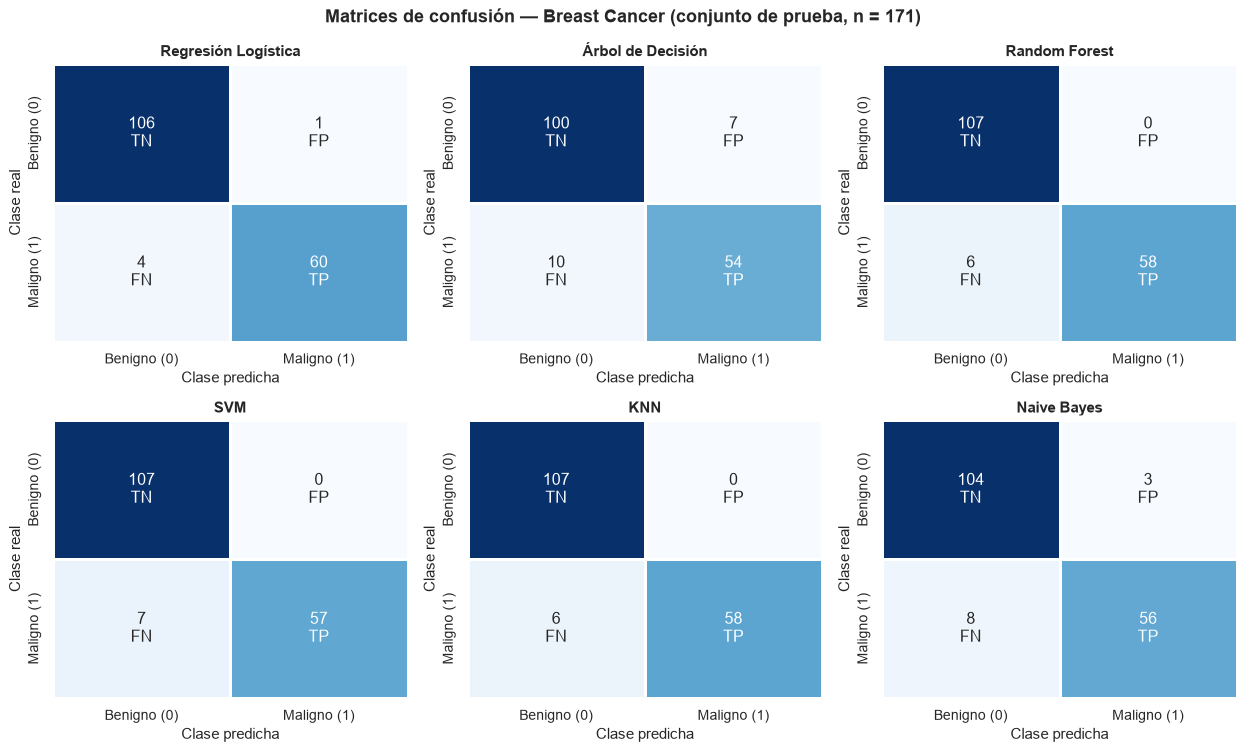

In [18]:
graficar_matrices(cms_cancer, ETIQUETAS_CANCER,
                  "Matrices de confusión — Breast Cancer (conjunto de prueba, n = 171)")

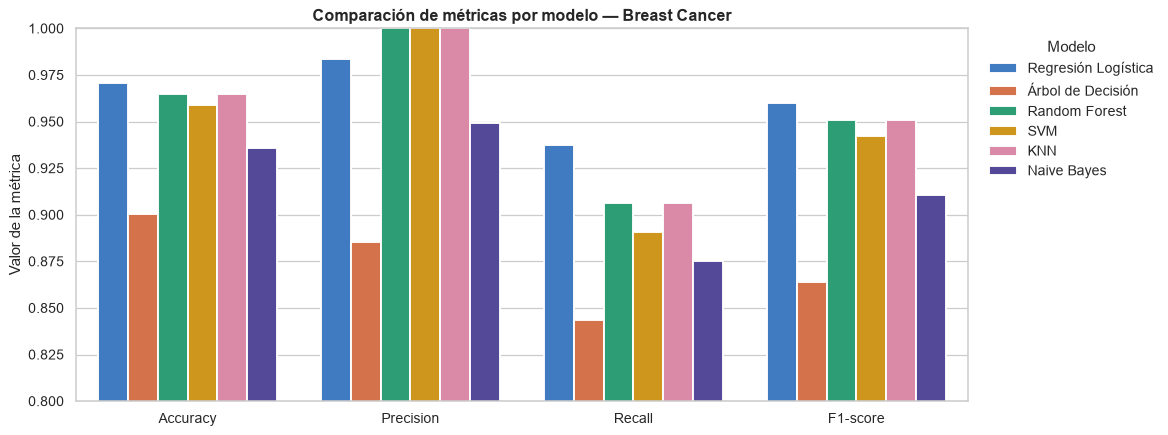

In [19]:
graficar_metricas(res_cancer, "Comparación de métricas por modelo — Breast Cancer", ymin=0.80)

Mejor modelo (Breast Cancer): Regresión Logística | Recall=0.938 | F1=0.960 | FN=4


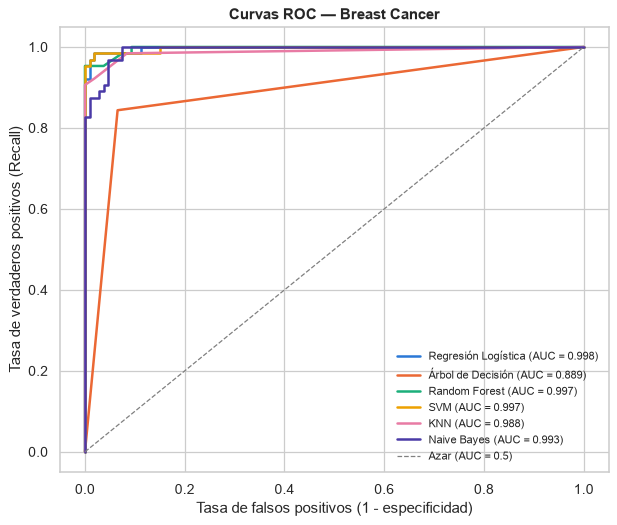

In [20]:
# Curvas ROC: equilibrio sensibilidad / (1 - especificidad) para todos los umbrales
fig, ax = plt.subplots(figsize=(7, 6))
for nombre, y_prob in probs_cancer.items():
    fpr, tpr, _ = roc_curve(yc_test, y_prob)
    auc = res_cancer.set_index("Modelo").loc[nombre, "ROC-AUC"]
    ax.plot(fpr, tpr, lw=2, color=COLORES[nombre], label=f"{nombre} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1, label="Azar (AUC = 0.5)")
ax.set_xlabel("Tasa de falsos positivos (1 - especificidad)")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.set_title("Curvas ROC — Breast Cancer", fontweight="bold")
ax.legend(loc="lower right", fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

mejor_c = res_cancer.sort_values(["Recall", "F1-score", "ROC-AUC"], ascending=False).iloc[0]
print(f"Mejor modelo (Breast Cancer): {mejor_c['Modelo']} | Recall={mejor_c['Recall']:.3f} | "
      f"F1={mejor_c['F1-score']:.3f} | FN={mejor_c['FN']}")

# 14. Interpretación de resultados

### 14.1 Caso de estudio: interpretación de cada métrica para cada modelo

**Conjunto de prueba (6 lotes: 3 defectuosos y 3 no defectuosos).** Los seis modelos obtienen TN = 3, FP = 0, FN = 0, TP = 3, por lo que todas las métricas valen 1.000. En términos del negocio de XYZ Inc.:

| Métrica | Valor (6 modelos) | Interpretación para la empresa |
|---|---|---|
| Accuracy | 1.000 | Los 6 lotes de prueba fueron clasificados correctamente. |
| Precision | 1.000 | Ningún lote bueno fue enviado a inspección innecesaria (FP = 0): no hay costo de reproceso injustificado. |
| **Recall** | **1.000** | **Ningún lote defectuoso fue liberado (FN = 0): ningún defecto llegaría al cliente.** |
| Especificidad | 1.000 | Todos los lotes buenos fueron reconocidos como buenos. |
| F1-score | 1.000 | Equilibrio perfecto entre detectar defectos y evitar falsas alarmas. |
| ROC-AUC | 1.000 | Todos los modelos ordenan a los lotes defectuosos por encima de los buenos. |
| CV Accuracy (5 particiones, 20 lotes) | 1.000 (Árbol: 0.950) | El Árbol de Decisión es el único que falla en una partición. |

**Evaluación exigente (100 particiones + Leave-One-Out).** Aquí sí aparecen diferencias:

| Modelo | Accuracy | Precision | Recall | F1 (± desv.) | Errores LOO | Interpretación |
|---|---|---|---|---|---|---|
| **Regresión Logística** | **1.000** | **1.000** | **1.000** | **1.000 ± 0.000** | **0** | Perfecto y totalmente estable: nunca libera un lote defectuoso ni genera falsas alarmas. |
| Random Forest | 1.000 | 1.000 | 1.000 | 1.000 ± 0.000 | 0 | Igual de exacto y estable que la Regresión Logística, pero con 100 árboles es menos explicable. |
| Naive Bayes | 0.995 | 0.993 | 1.000 | 0.996 ± 0.028 | 0 | Detecta todos los defectos; ocasionalmente marca un lote bueno como defectuoso. |
| SVM | 0.993 | 0.990 | 1.000 | 0.994 ± 0.034 | 0 | Detecta todos los defectos; algunas falsas alarmas aisladas. |
| KNN | 0.988 | 0.987 | 0.997 | 0.990 ± 0.044 | 0 | En contadas particiones deja escapar un defecto: depende de qué lotes sean sus vecinos. |
| Árbol de Decisión | 0.970 | 0.963 | **0.983** | 0.969 ± 0.121 | 1 FP | El más inestable: en algunas particiones **libera lotes defectuosos** (Recall < 1) y genera falsas alarmas. |

**Probabilidades y casos frontera.** El *Lote 4* (80 °, 6 h, vibración 2.0) es el lote de prueba más cercano al umbral: KNN le asigna 0.40 de probabilidad de defecto y la Regresión Logística 0.27. Es correcto clasificarlo como no defectuoso, pero conviene vigilar lotes con este perfil. Los árboles, Random Forest y Naive Bayes entregan probabilidades extremas (0 o 1), lo que transmite una seguridad que 14 lotes de entrenamiento no justifican.

**Interpretabilidad.** La Regresión Logística indica que, por cada desviación estándar adicional, la razón de probabilidades de defecto se multiplica por **2.04 (presión), 1.90 (temperatura), 1.87 (vibración) y 1.80 (horas de operación)**, y por **0.53 (velocidad)**: a mayor velocidad, menor riesgo. Random Forest reparte la importancia de forma similar entre las cinco variables (0.15–0.23), porque todas describen el mismo fenómeno de desgaste. El Árbol de Decisión, en cambio, resume todo en **una sola regla: `horas_operacion ≤ 7.5` → no defectuoso**.

**Lote nuevo (frontera: 84 °, 7 h).** Cinco modelos recomiendan **inspeccionar** el lote (P(defecto) entre 0.59 y 0.96), pero el **Árbol de Decisión lo libera con probabilidad 0**, porque solo mira las horas de operación (7 < 7.5) e ignora que la temperatura ya supera el umbral observado (84 > 83.5). Este es exactamente el **falso negativo** que la guía pide evitar.

**Mejor modelo para XYZ Inc.: Regresión Logística.** Empata con Random Forest en todas las métricas (incluida la evaluación de 100 particiones), y el desempate se resuelve con los criterios del curso: es más **interpretable** (coeficientes y *odds ratios* accionables para el área de producción), más **rápida** y de menor **costo computacional**, y entrega probabilidades moderadas que permiten fijar un umbral conservador (p. ej., inspeccionar todo lote con P(defecto) ≥ 0.30).

### 14.2 Validación complementaria: Breast Cancer (171 casos de prueba)

| Modelo | Accuracy | Precision | Recall | F1 | ROC-AUC | FN | FP |
|---|---|---|---|---|---|---|---|
| **Regresión Logística** | **0.971** | 0.984 | **0.938** | **0.960** | **0.998** | **4** | 1 |
| Random Forest | 0.965 | 1.000 | 0.906 | 0.951 | 0.997 | 6 | 0 |
| KNN | 0.965 | 1.000 | 0.906 | 0.951 | 0.988 | 6 | 0 |
| SVM | 0.959 | 1.000 | 0.891 | 0.942 | 0.997 | 7 | 0 |
| Naive Bayes | 0.936 | 0.949 | 0.875 | 0.911 | 0.993 | 8 | 3 |
| Árbol de Decisión | 0.901 | 0.885 | 0.844 | 0.864 | 0.889 | 10 | 7 |

Con 569 registros el patrón del caso de producción se confirma y se amplifica: la **Regresión Logística** vuelve a ser el mejor modelo (menos falsos negativos) y el **Árbol de Decisión** el más débil (10 FN, 7 FP). Random Forest reduce los errores del árbol de 17 a 6, lo que demuestra en la práctica el efecto del *bagging*.

# 15. Conclusiones

1. **Se cumplió la actividad de la guía:** el script `C1_CasoProduccion.py` se amplió con todas las métricas estudiadas (Accuracy, Precision, Recall, Especificidad, F1-score, ROC-AUC, validación cruzada y matriz de confusión), y cada una se interpretó para los seis modelos.
2. **En el conjunto de prueba original los seis modelos son perfectos**, pero eso se explica por un dataset pequeño (20 lotes) y separable. Las métricas sobre 6 lotes no bastan para elegir un modelo.
3. **La evaluación exigente sí diferencia a los modelos:** solo la Regresión Logística y Random Forest mantienen un desempeño perfecto en 100 particiones; el Árbol de Decisión es el más inestable y el único que llega a liberar lotes defectuosos.
4. **El Árbol de Decisión es peligroso en este caso:** su regla única (`horas_operacion ≤ 7.5`) liberó un lote frontera que los otros cinco modelos enviaron a inspección, que es el falso negativo que la guía pide evitar.
5. **Modelo recomendado: Regresión Logística**, por su Recall perfecto y estable, su interpretabilidad (presión, temperatura, vibración y horas de operación aumentan el riesgo; la velocidad lo reduce) y su bajo costo computacional. La validación con *Breast Cancer* confirma que es el modelo más confiable también con más datos.
6. **Recomendación a XYZ Inc.:** recolectar un histórico más amplio de lotes antes del despliegue, fijar un umbral conservador de probabilidad para inspección y monitorear las variables de desgaste (temperatura y horas de operación). Como dice la guía: *el mejor modelo no siempre es el que acierta, sino el que mejor ayuda a prevenir defectos antes de que lleguen al cliente*.